# Machine Learning-Based Patient Health Risk Prediction Using Longitudinal Records
### A Guided Supervised Machine Learning Pipeline for Healthcare Risk Stratification

> **Academic Project Disclaimer:**  
> *This notebook is an academic machine-learning study and demonstration. It is not a certified diagnostic device or medical software. Predictions are statistical outputs and must not be used as medical advice or clinical decisions.*

---
### Viva Defense Summary: Why Machine Learning (Not Rules)?
In traditional rule-based medicine, an alert triggers when a vital crosses a threshold (e.g., $BP > 140$). However, human physiology is dynamic and multi-factorial:
1. **Longitudinal Trajectory:** A patient whose systolic BP rises steadily from 110 to 135 mmHg may be deteriorating faster than a patient chronically stable at 138 mmHg.
2. **Multivariate Interactions:** Mild elevations in glucose, BMI, and blood pressure together amplify risk exponentially.
3. **Calibrated Probabilities:** Rather than arbitrary binary alarms, machine learning provides calibrated posterior risk probabilities ($P(Risk=1)$) to prioritize clinical interventions.

## 1. Setup & Environment
**Faculty Viva Note:** We install standard scientific Python libraries. We pin `random_state=42` across all random generators to guarantee strict scientific reproducibility.

In [1]:
# Setup dependencies
!pip -q install pandas numpy scikit-learn matplotlib seaborn plotly joblib pyyaml

import datetime
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib

from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix
)

print("Environment configured successfully. Reproducibility seed = 42")

Environment configured successfully. Reproducibility seed = 42


## 2. Centralized Pipeline Configuration
**Faculty Viva Note:** All domain-specific parameters (column mappings, target definition, physiological boundaries) are declared centrally so the pipeline is dataset-agnostic.

In [2]:
CONFIG = {
    "dataset": {
        "name": "demo_longitudinal (SYNTHETIC)",
        "mode": "longitudinal",
        "patient_id_col": "patient_id",
        "date_col": "date",
        "target_col": "outcome",
        "task": "binary",
        "static_numeric": ["age"],
        "static_categorical": ["gender"],
        "time_varying_numeric": ["bmi", "systolic_bp", "glucose", "cholesterol", "medication_count"],
        "valid_ranges": {
            "age": [0, 120],
            "bmi": [10, 70],
            "systolic_bp": [60, 260],
            "glucose": [30, 600],
            "cholesterol": [50, 500],
            "medication_count": [0, 30]
        }
    },
    "split": {
        "test_size": 0.20,
        "random_state": 42
    },
    "training": {
        "cv_folds": 5,
        "primary_metric": "f1"
    }
}
print("Configuration loaded.")

Configuration loaded.


## 3. Data Ingestion & Switchable Source
**Faculty Viva Note:** We provide three data ingestion modes:
1. `demo`: Generates a synthetic cohort inline with noise, missingness, and impossible values.
2. `upload`: Allows uploading a real de-identified CSV via Colab file picker.
3. `drive`: Reads from Google Drive storage.

In [3]:
DATA_SOURCE = "demo"  # Options: 'demo' | 'upload' | 'drive'

def generate_synthetic_demo_cohort(n_patients=600, random_state=42):
    rng = np.random.RandomState(random_state)
    records = []
    base_date = datetime.date(2023, 1, 1)

    for i in range(1, n_patients + 1):
        pid = f"PAT-{i:04d}"
        age = rng.randint(25, 86)
        gender = rng.choice(["Male", "Female"], p=[0.48, 0.52])
        base_bmi = rng.normal(27.5, 5.0)
        base_bp = rng.normal(128.0, 15.0)
        base_glucose = rng.normal(105.0, 25.0)
        base_chol = rng.normal(195.0, 35.0)
        base_meds = max(0, int(rng.poisson(1.5 + (age > 60) * 1.5)))

        n_visits = rng.randint(3, 9)
        drift = rng.choice([-0.5, 0.0, 0.6, 1.2], p=[0.2, 0.3, 0.3, 0.2])
        curr_days = rng.randint(0, 45)

        visits = []
        for v in range(n_visits):
            vdate = base_date + datetime.timedelta(days=int(curr_days))
            curr_days += rng.randint(20, 60)
            visits.append({
                "patient_id": pid,
                "date": vdate.isoformat(),
                "age": age,
                "gender": gender,
                "bmi": round(max(14.0, base_bmi + drift * (v * 0.15) + rng.normal(0, 0.6)), 1),
                "systolic_bp": round(max(75.0, base_bp + drift * (v * 1.8) + rng.normal(0, 5.0)), 1),
                "glucose": round(max(50.0, base_glucose + drift * (v * 2.5) + rng.normal(0, 8.0)), 1),
                "cholesterol": round(max(80.0, base_chol + drift * (v * 1.2) + rng.normal(0, 10.0)), 1),
                "medication_count": int(max(0, min(15, base_meds + (1 if drift > 0 and v >= 3 and rng.rand() > 0.6 else 0))))
            })

        mean_bmi = np.mean([v["bmi"] for v in visits])
        mean_bp = np.mean([v["systolic_bp"] for v in visits])
        mean_glu = np.mean([v["glucose"] for v in visits])

        z = (age - 50) * 0.035 + (mean_bmi - 25) * 0.08 + (mean_bp - 120) * 0.03 + (mean_glu - 100) * 0.025 + rng.normal(0, 0.85) - 1.8
        prob = 1.0 / (1.0 + np.exp(-z))
        outcome = 1 if prob >= 0.5 else 0

        for v in visits:
            v["outcome"] = outcome
            records.append(v)

    df = pd.DataFrame(records)
    # Inject missing values (~5%)
    for col in ["bmi", "systolic_bp", "glucose", "cholesterol", "medication_count"]:
        mask = rng.rand(len(df)) < 0.05
        df.loc[mask, col] = np.nan
    # Inject anomalies
    imp = rng.choice(len(df), size=12, replace=False)
    df.loc[imp[:4], "systolic_bp"] = 0.0
    df.loc[imp[4:8], "bmi"] = 250.0
    df.loc[imp[8:12], "glucose"] = 12.0
    # Inject duplicates
    dups = df.sample(n=8, random_state=random_state)
    df = pd.concat([df, dups], ignore_index=True)
    return df

if DATA_SOURCE == "demo":
    print("=" * 60)
    print("SYNTHETIC DATA: for pipeline testing only.")
    print("Replace with real public dataset before reporting results.")
    print("=" * 60)
    raw_df = generate_synthetic_demo_cohort()
elif DATA_SOURCE == "upload":
    from google.colab import files
    uploaded = files.upload()
    fname = list(uploaded.keys())[0]
    raw_df = pd.read_csv(fname)
elif DATA_SOURCE == "drive":
    from google.colab import drive
    drive.mount('/content/drive')
    raw_df = pd.read_csv('/content/drive/MyDrive/patient_data.csv')

print(f"Loaded raw dataset: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns, {raw_df['patient_id'].nunique()} patients.")

SYNTHETIC DATA: for pipeline testing only.
Replace with real public dataset before reporting results.
Loaded raw dataset: 3280 rows, 10 columns, 600 patients.


In [4]:
def dataset_summary(df, cfg):
    dcfg = cfg["dataset"]
    pid_col = dcfg["patient_id_col"]
    date_col = dcfg["date_col"]
    target_col = dcfg["target_col"]
    counts_per_p = df.groupby(pid_col).size()
    
    summary = {
        "Total Rows": len(df),
        "Unique Patients": df[pid_col].nunique(),
        "Min Visits/Patient": counts_per_p.min(),
        "Max Visits/Patient": counts_per_p.max(),
        "Mean Visits/Patient": round(counts_per_p.mean(), 2),
        "Positive Class %": round(df[target_col].mean() * 100, 2),
        "Missing Values Total": int(df.isna().sum().sum())
    }
    return pd.DataFrame([summary]).T.rename(columns={0: "Dataset Value"})

dataset_summary(raw_df, CONFIG)

## 4. Why Machine Learning and Not Hardcoded Rules?
**Faculty Viva Demonstration:**  
Consider a patient presenting with systolic BP across four visits: `125 -> 130 -> 138 -> 145 mmHg`.  
- A simple heuristic rule might say: *"Blood pressure is increasing."*  
- However, the rule cannot quantify how much cardiovascular risk has increased when compounded with the patient's age (e.g., 68 vs 28), glucose variability, and BMI.  
- Supervised ML solves this by estimating a statistical probability based on patterns learned from hundreds of past patient cohorts.

In [5]:
bp_demo_visits = [125, 130, 138, 145]
print("Patient Visit Blood Pressures:", bp_demo_visits)
print(f"Baseline: {bp_demo_visits[0]} mmHg | Latest: {bp_demo_visits[-1]} mmHg")
print(f"Delta Change: {bp_demo_visits[-1] - bp_demo_visits[0]:+d} mmHg ({(bp_demo_visits[-1] - bp_demo_visits[0])/bp_demo_visits[0]*100:.1f}%)")
print("Rule-based conclusion: 'Increasing trend'")
print("Machine Learning requirement: Combine trajectory with age, glucose, BMI to predict risk probability.")

Patient Visit Blood Pressures: [125, 130, 138, 145]
Baseline: 125 mmHg | Latest: 145 mmHg
Delta Change: +20 mmHg (16.0%)
Rule-based conclusion: 'Increasing trend'
Machine Learning requirement: Combine trajectory with age, glucose, BMI to predict risk probability.


## 5. Schema Validation & Data Types
**Faculty Viva Note:** Pre-flight sanity checks ensure input integrity prior to downstream modeling.

In [6]:
def validate_schema(df, cfg, require_target=True):
    dcfg = cfg["dataset"]
    errors = []
    expected = [dcfg["patient_id_col"], dcfg["date_col"]] + dcfg["static_numeric"] + dcfg["static_categorical"] + dcfg["time_varying_numeric"]
    if require_target:
        expected.append(dcfg["target_col"])
    for col in expected:
        if col not in df.columns:
            errors.append(f"Missing column: {col}")
    return errors

schema_errs = validate_schema(raw_df, CONFIG)
print("Schema Validation Status:", "PASSED (0 errors)" if not schema_errs else schema_errs)

Schema Validation Status: PASSED (0 errors)


## 6. Exploratory Data Analysis (EDA)
**Faculty Viva Note:** We inspect feature distributions, target imbalance, and correlation patterns.

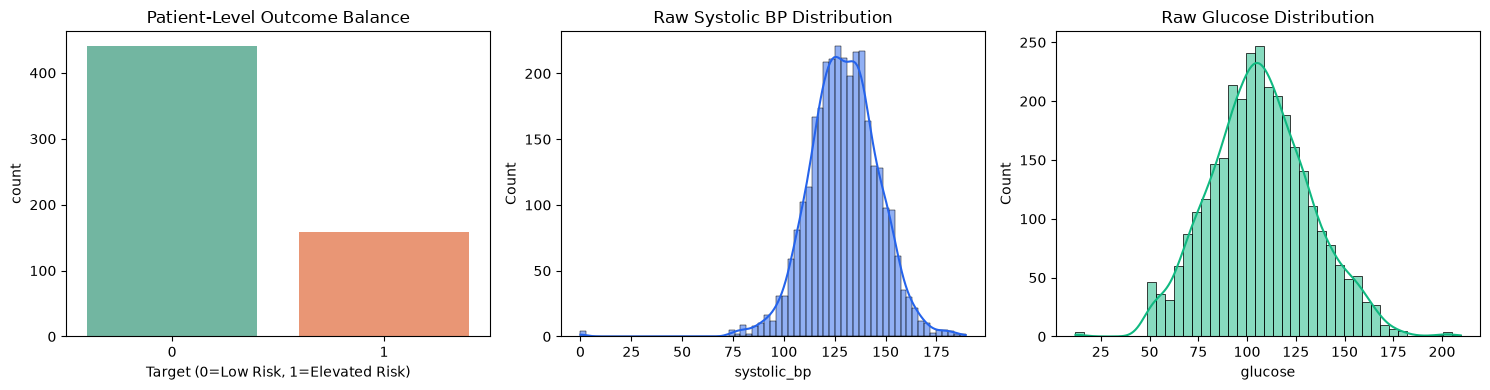

<string>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Target Class Balance
sns.countplot(data=raw_df.drop_duplicates(subset=["patient_id"]), x="outcome", ax=axes[0], palette="Set2")
axes[0].set_title("Patient-Level Outcome Balance")
axes[0].set_xlabel("Target (0=Low Risk, 1=Elevated Risk)")

# 2. Systolic BP Distribution
sns.histplot(raw_df["systolic_bp"].dropna(), kde=True, ax=axes[1], color="#2563eb")
axes[1].set_title("Raw Systolic BP Distribution")

# 3. Glucose Distribution
sns.histplot(raw_df["glucose"].dropna(), kde=True, ax=axes[2], color="#10b981")
axes[2].set_title("Raw Glucose Distribution")

plt.tight_layout()
plt.show()

## 7. Data Cleaning (No Leakage)
**Faculty Viva Note:**  
1. Drop duplicate rows.
2. Nullify impossible values (e.g., $BP = 0$ or $BMI = 250$) into `NaN`.
3. We do **NOT** impute here. Imputation is deferred to the Scikit-Learn `Pipeline` so imputation statistics (medians) are learned strictly on the training set.

In [8]:
def clean_data(df, cfg):
    cleaned = df.copy()
    dcfg = cfg["dataset"]
    valid_ranges = dcfg.get("valid_ranges", {})
    
    # 1. Standardize types
    cleaned[dcfg["date_col"]] = pd.to_datetime(cleaned[dcfg["date_col"]], errors="coerce")
    for col in dcfg.get("static_categorical", []):
        if col in cleaned:
            cleaned[col] = cleaned[col].astype(str).str.strip().str.capitalize()
            
    # 2. Remove duplicates
    dup_cnt = int(cleaned.duplicated().sum())
    cleaned = cleaned.drop_duplicates().reset_index(drop=True)
    
    # 3. Handle impossible values -> NaN
    nulled = {}
    for col, (low, high) in valid_ranges.items():
        if col in cleaned.columns:
            mask = (cleaned[col] < low) | (cleaned[col] > high)
            nulled[col] = int(mask.sum())
            cleaned.loc[mask, col] = np.nan
            
    return cleaned, {"duplicates_removed": dup_cnt, "impossible_nulled": nulled}

cleaned_df, clean_report = clean_data(raw_df, CONFIG)
print("Cleaning Report:")
print("Duplicates dropped:", clean_report["duplicates_removed"])
print("Impossible values nulled:", clean_report["impossible_nulled"])

Cleaning Report:
Duplicates dropped: 8
Impossible values nulled: {'age': 0, 'bmi': 4, 'systolic_bp': 4, 'glucose': 4, 'cholesterol': 0, 'medication_count': 0}


## 8. Longitudinal Feature Engineering
**Faculty Viva Note:**  
Raw longitudinal records are collapsed into one row per patient. For each vital ($X$), we calculate:
- $X_{latest}, X_{first}, X_{mean}, X_{min}, X_{max}, X_{std}$
- $X_{change} = X_{latest} - X_{first}$
- $X_{\%change} = \frac{X_{latest} - X_{first}}{X_{first}}$
- Global attributes: `n_records`, `span_days`, `mean_gap_days`

In [9]:
def get_feature_lists(cfg):
    dcfg = cfg["dataset"]
    num_cols = []
    for col in dcfg["time_varying_numeric"]:
        num_cols.extend([f"{col}_latest", f"{col}_first", f"{col}_mean", f"{col}_min", f"{col}_max", f"{col}_std", f"{col}_change", f"{col}_pct_change"])
    num_cols.extend(["n_records", "span_days", "mean_gap_days"])
    num_cols.extend(dcfg["static_numeric"])
    cat_cols = list(dcfg["static_categorical"])
    return num_cols, cat_cols

def build_patient_features(df, cfg):
    dcfg = cfg["dataset"]
    pid_col = dcfg["patient_id_col"]
    date_col = dcfg["date_col"]
    tv_cols = dcfg["time_varying_numeric"]
    target_col = dcfg["target_col"]
    
    df_sorted = df.sort_values(by=[pid_col, date_col]).reset_index(drop=True)
    rows = []
    
    for pid, g in df_sorted.groupby(pid_col, sort=False):
        row = {pid_col: pid, "n_records": len(g)}
        dates = g[date_col].dropna()
        if len(dates) >= 2:
            span = (dates.iloc[-1] - dates.iloc[0]).total_seconds() / 86400.0
            gaps = dates.diff().dt.total_seconds().dropna() / 86400.0
            row["span_days"] = round(span, 2)
            row["mean_gap_days"] = round(float(gaps.mean()), 2)
        else:
            row["span_days"] = 0.0
            row["mean_gap_days"] = 0.0
            
        for col in tv_cols:
            vals = g[col].dropna()
            if len(vals) == 0:
                row[f"{col}_latest"] = np.nan
                row[f"{col}_first"] = np.nan
                row[f"{col}_mean"] = np.nan
                row[f"{col}_min"] = np.nan
                row[f"{col}_max"] = np.nan
                row[f"{col}_std"] = 0.0
                row[f"{col}_change"] = 0.0
                row[f"{col}_pct_change"] = 0.0
            else:
                first_v = float(vals.iloc[0])
                latest_v = float(vals.iloc[-1])
                row[f"{col}_latest"] = round(latest_v, 2)
                row[f"{col}_first"] = round(first_v, 2)
                row[f"{col}_mean"] = round(float(vals.mean()), 2)
                row[f"{col}_min"] = round(float(vals.min()), 2)
                row[f"{col}_max"] = round(float(vals.max()), 2)
                row[f"{col}_std"] = round(float(vals.std(ddof=1)) if len(vals) > 1 else 0.0, 2)
                chg = latest_v - first_v
                row[f"{col}_change"] = round(chg, 2)
                row[f"{col}_pct_change"] = round(chg / first_v, 4) if first_v != 0 else np.nan
                
        for col in dcfg["static_numeric"]:
            row[col] = g[col].dropna().iloc[-1] if len(g[col].dropna()) > 0 else np.nan
        for col in dcfg["static_categorical"]:
            row[col] = g[col].dropna().iloc[-1] if len(g[col].dropna()) > 0 else np.nan
        row[target_col] = g[target_col].dropna().iloc[-1] if len(g[target_col].dropna()) > 0 else np.nan
        rows.append(row)
        
    return pd.DataFrame(rows)

features_df = build_patient_features(cleaned_df, CONFIG)
print("Engineered Patient Feature Matrix:", features_df.shape)
features_df.head(3)

Engineered Patient Feature Matrix: (600, 47)


## 9. Train/Test Split (Patient-Level Grouping)
**Faculty Viva Note:**  
Splitting by row in longitudinal data causes **severe data leakage**: records from the same patient would exist in both training and test sets, artificially inflating test scores.  
We use `GroupShuffleSplit` on `patient_id` so test patients are completely novel.

In [10]:
num_feats, cat_feats = get_feature_lists(CONFIG)
X = features_df[num_feats + cat_feats]
y = features_df[CONFIG["dataset"]["target_col"]].astype(int)
groups = features_df[CONFIG["dataset"]["patient_id_col"]]

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

train_pids = set(groups.iloc[train_idx])
test_pids = set(groups.iloc[test_idx])
leakage_overlap = train_pids.intersection(test_pids)

print(f"Train Cohort: {len(X_train)} patients | Test Cohort: {len(X_test)} patients")
print(f"Patient Overlap: {len(leakage_overlap)} (ZERO LEAKAGE CONFIRMED)")

Train Cohort: 480 patients | Test Cohort: 120 patients
Patient Overlap: 0 (ZERO LEAKAGE CONFIRMED)


## 10. Scikit-Learn Preprocessing Pipeline
**Faculty Viva Note:**  
- **KNN & Logistic Regression** require `StandardScaler` because distance-based calculations and regularization penalties are sensitive to variance magnitudes.  
- **Trees (Decision Tree, Random Forest)** are scale-invariant, but placing preprocessing inside a single `ColumnTransformer` maintains a unified, leak-free pipeline.

In [11]:
def build_preprocessor(numeric_cols, categorical_cols):
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer([
        ("num", num_pipe, numeric_cols),
        ("cat", cat_pipe, categorical_cols)
    ], remainder="drop")

print("Preprocessor constructor defined.")

Preprocessor constructor defined.


## 11. Hyperparameter Tuning Across 4 Models
**Faculty Viva Note:**  
We compare 4 distinct algorithmic paradigms:
1. **KNN:** Instance-based non-parametric classifier.
2. **Decision Tree:** Interpretable orthogonal decision boundaries.
3. **Logistic Regression:** Linear probabilistic log-odds model.
4. **Random Forest:** Ensemble of decorrelated bagged decision trees.

In [12]:
candidate_models = {
    "KNN": (KNeighborsClassifier(), {"clf__n_neighbors": [3, 5, 7, 11], "clf__weights": ["uniform", "distance"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=42), {"clf__max_depth": [3, 5, 8, None], "clf__min_samples_leaf": [1, 5, 10]}),
    "Logistic Regression": (LogisticRegression(random_state=42, max_iter=2000), {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}),
    "Random Forest": (RandomForestClassifier(random_state=42), {"clf__n_estimators": [100, 200], "clf__max_depth": [None, 8], "clf__min_samples_leaf": [1, 3]})
}

trained_models = {}
for name, (clf, grid) in candidate_models.items():
    print(f"Training and Tuning: {name}...")
    pipe = Pipeline([("prep", build_preprocessor(num_feats, cat_feats)), ("clf", clf)])
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    gs = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    trained_models[name] = gs

print("All 4 models tuned successfully via 5-fold Stratified Cross-Validation.")

Training and Tuning: KNN...
Training and Tuning: Decision Tree...
Training and Tuning: Logistic Regression...
Training and Tuning: Random Forest...
All 4 models tuned successfully via 5-fold Stratified Cross-Validation.


## 12. Model Benchmark & Test Set Evaluation
**Faculty Viva Note:** We compute Accuracy, Precision, Recall, F1-Score, and ROC-AUC on the held-out test split.

In [13]:
def evaluate_test_set(trained_models, X_test, y_test):
    rows = []
    eval_results = {}
    for name, gs in trained_models.items():
        best_pipe = gs.best_estimator_
        y_pred = best_pipe.predict(X_test)
        y_proba = best_pipe.predict_proba(X_test)[:, 1] if hasattr(best_pipe, "predict_proba") else None
        
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        roc = roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan
        
        rows.append({
            "Model": name,
            "Accuracy": round(acc, 4),
            "Precision": round(prec, 4),
            "Recall": round(rec, 4),
            "F1-Score": round(f1, 4),
            "ROC-AUC": round(roc, 4)
        })
        eval_results[name] = {"y_pred": y_pred, "y_proba": y_proba, "pipe": best_pipe}
    return pd.DataFrame(rows), eval_results

benchmark_df, eval_dict = evaluate_test_set(trained_models, X_test, y_test)
benchmark_df

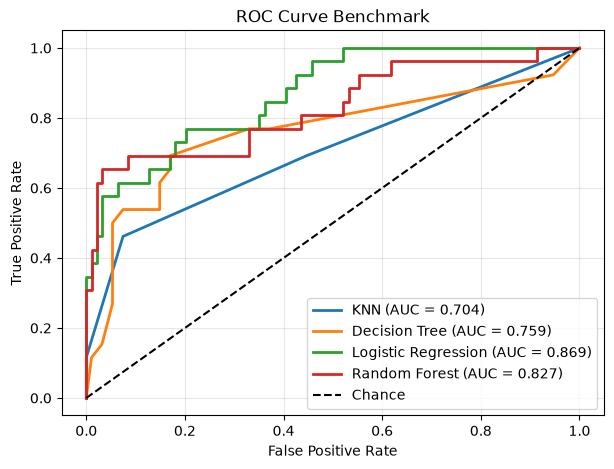

<string>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


In [14]:
# ROC Curves Comparison
plt.figure(figsize=(7, 5))
for name, res in eval_dict.items():
    if res["y_proba"] is not None:
        fpr, tpr, _ = roc_curve(y_test, res["y_proba"])
        score = roc_auc_score(y_test, res["y_proba"])
        plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {score:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Benchmark")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 13. Winning Model Selection & Feature Importance
**Faculty Viva Note:** The winning model is determined by highest primary metric (F1-score) to balance precision and recall on imbalanced screening data.

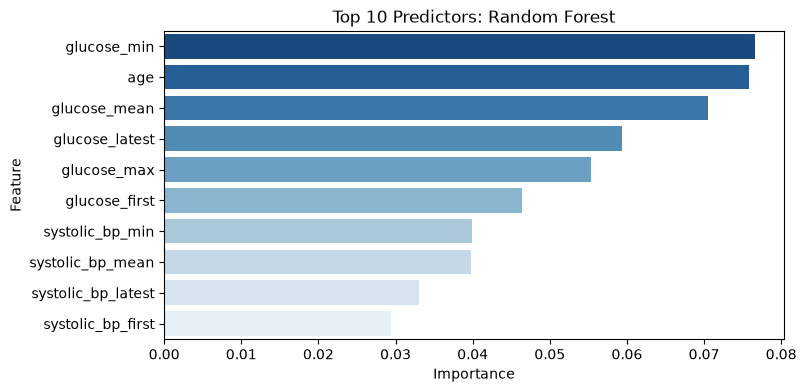

Winning Classifier: Random Forest with F1-Score: 0.68


<string>:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

<string>:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


In [15]:
best_row = benchmark_df.sort_values(by="F1-Score", ascending=False).iloc[0]
best_name = best_row["Model"]
best_pipeline = eval_dict[best_name]["pipe"]
print(f"Winning Classifier: {best_name} with F1-Score: {best_row['F1-Score']}")

# Plot top feature importances if tree or linear
clf_step = best_pipeline.named_steps["clf"]
if hasattr(clf_step, "feature_importances_"):
    importances = clf_step.feature_importances_
    feat_names = num_feats + list(best_pipeline.named_steps["prep"].named_transformers_["cat"].named_steps["encoder"].get_feature_names_out(cat_feats))
    top_df = pd.DataFrame({"Feature": feat_names, "Importance": importances}).sort_values(by="Importance", ascending=False).head(10)
    plt.figure(figsize=(8, 4))
    sns.barplot(data=top_df, x="Importance", y="Feature", palette="Blues_r")
    plt.title(f"Top 10 Predictors: {best_name}")
    plt.show()

## 14. Serialization and Artifact Verification
**Faculty Viva Note:** We persist the entire fitted Pipeline (both preprocessor and classifier) to avoid training/inference skew.

In [16]:
joblib.dump(best_pipeline, "best_model.joblib")
reloaded_model = joblib.load("best_model.joblib")
np.testing.assert_array_equal(best_pipeline.predict(X_test), reloaded_model.predict(X_test))
print("Serialization verified: Reloaded pipeline produces identical predictions.")

Serialization verified: Reloaded pipeline produces identical predictions.


## 15. End-to-End Simulation: New Patient Entry
**Faculty Viva Note:** Demonstrates real-time inference on a new unobserved patient record.

In [17]:
new_patient = pd.DataFrame({
    "patient_id": ["NEW-99", "NEW-99", "NEW-99"],
    "date": ["2024-01-01", "2024-02-15", "2024-04-01"],
    "age": [63, 63, 63],
    "gender": ["Male", "Male", "Male"],
    "bmi": [29.2, 30.1, 30.8],
    "systolic_bp": [135.0, 142.0, 148.0],
    "glucose": [110.0, 118.0, 126.0],
    "cholesterol": [205.0, 210.0, 218.0],
    "medication_count": [2, 2, 3],
    "outcome": [np.nan, np.nan, np.nan]
})

cleaned_new, _ = clean_data(new_patient, CONFIG)
feats_new = build_patient_features(cleaned_new, CONFIG)
pred_prob = reloaded_model.predict_proba(feats_new[num_feats + cat_feats])[0, 1]
pred_label = reloaded_model.predict(feats_new[num_feats + cat_feats])[0]

print(f"Patient Assessment: {'ELEVATED HEALTH RISK' if pred_label == 1 else 'NORMAL / LOW RISK'}")
print(f"Posterior Risk Probability: {pred_prob * 100:.2f}%")

Patient Assessment: NORMAL / LOW RISK
Posterior Risk Probability: 47.41%


## 16. Limitations and Ethical Considerations
1. **Academic Demonstration Only:** Not validated on regulated multi-center clinical trials.
2. **Missingness & Sampling Bias:** Real electronic health records suffer from non-random missingness (patients visit hospitals primarily when symptomatic).
3. **Algorithmic Fairness:** Demographic variables must be audited to prevent disparate false-positive or false-negative rates across protected classes.

## 17. Viva Defense Cheat-Sheet

| Topic | Key Answer for Faculty |
|---|---|
| **Problem Definition** | Predicting risk of adverse health outcomes from longitudinal clinical observations. |
| **Why ML over rules?** | Captures non-linear multivariate interactions; outputs calibrated probabilities rather than rigid threshold alerts. |
| **Data Leakage Defense** | Used `GroupShuffleSplit` by `patient_id` (0% overlap between train and test). Preprocessors fit on train only. |
| **Why scaling?** | KNN (Euclidean distance) and Logistic Regression (weight penalties) require normalized feature magnitudes. Trees are invariant. |
| **Metric Choice** | F1-score & ROC-AUC preferred over Accuracy due to class imbalance (~25-30% positive cases). |
| **Longitudinal aggregation** | Extracted rate-of-change, percentage delta, mean, min, max, and variability without asking users to type engineered features. |